# Sequence lab 2 · Explain the Transformer forecaster: which channel, which moment, and is attention the answer?

**Author:** Xiangqi Kong

**Follows:** the earlier lab *Transformer for Time Series* (same building blocks, now in PyTorch) and *Sequence lab 1* · **Decks:** Post-hoc Model-Agnostic (*PCI*), Post-hoc Model-Specific (*Integrated Gradients*, *Attention*) · **Runtime:** about 2 minutes on a T4, about 4 minutes on CPU · **GPU:** helps

In the earlier lab you built an encoder-decoder Transformer that reads **100 time steps of 10 channels** and forecasts the future. In that data every channel was generated on its own, so there was nothing to discover about how channels depend on each other.

Here the data gets a **known answer**, built in on purpose:

- **Channel 0, the leader,** carries sudden bumps that nothing can predict.
- **Channel 1, the follower,** is the leader **20 steps later**. So the next 20 steps of the follower are already visible, in the leader.
- **Channels 2–8** are independent waves, as in the earlier lab.
- **Channel 9** is pure noise: a control that no forecast should depend on.

A model that forecasts well **must** use this structure. So we know what a correct explanation looks like, and we can mark each method right or wrong:

1. **PCI** (model-agnostic): which input channel does each forecast need?
2. **Integrated Gradients** (model-specific): the same question for single forecasts, and then *which moment* of the leader the follower's forecast reads.
3. **Attention**: does the cross-attention map show the 20-step delay? Is the map an explanation?

Before you run anything, write down your guess: *will the attention map show the 20-step delay?*

> **Walkthrough version.** Nothing to fill in: the code is complete and the results are already shown, so you can read it without running it.
> **Every line of code has a plain comment above it** that says what it does and why, and after each result a **What to notice** note says what to look at.
> Read it before the lab, or open it next to the easy version when you are stuck.

> **In the lab session: about 30 minutes.** Do the sections marked 🟢 core in order; they are what we discuss at the end.
> Sections marked ⚪ if time can be skipped: no 🟢 core section needs them, so come back to them at home.
>
> 🟢 core: all sections: PCI (TODO 1), IG (TODO 2), attention and the replace-the-attention test (TODO 3).  
> ⚪ if time: the Try it ideas at the end.

## 0. Setup

> **What this cell does.** It loads the libraries, fixes the random seed and checks for a GPU. Just run it.

In [1]:
# time measures how long training takes.
import time

# NumPy = arrays, pandas = tables, matplotlib = plots.
import numpy as np, pandas as pd, matplotlib.pyplot as plt

# PyTorch and its neural-network building blocks.
import torch, torch.nn as nn

# spearmanr compares two rankings (1 = same order).
from scipy.stats import spearmanr

# Fix the random numbers, so everybody gets the same data and the same model.
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
# Use the GPU if there is one, otherwise the CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# A plain look for all plots, and three colours used below.
plt.rcParams.update(
    {"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110}
)
BLUE, RED, GREY = "#2563EB", "#DC2626", "#9CA3AF"
print("Device:", DEVICE, "| torch", torch.__version__)

Device: cpu | torch 2.15.0+cu132


## 1. The data: the earlier lab's waves, plus a known answer · 🟢 core

The generator follows the earlier notebook: each channel is a mix of 2–3 sine waves, a small trend and noise. Four things are changed, and each is marked in the code:

| Change | Why |
|---|---|
| The leader gets random **bumps** | a part of the signal that cannot be forecast from its own past |
| The follower **copies the leader 20 steps later** | the only way to forecast its bumps is to read the leader: the known answer |
| Channel 9 is **pure noise** | a control: its importance must be zero (the NOISE channel of the PCI lab) |
| Slower waves, and a forecast of **20 steps** (was 50) | so that a small model trains well in about a minute |

> **What this cell does.** It generates the data: 10 channels over time. Channel 0 (the leader) has random bumps; channel 1 (the follower) repeats the leader 20 steps later; channels 2 to 8 are separate waves; channel 9 is noise. Just run it.

X_train (16000, 100, 10) | X_test (2000, 100, 10) | Y_test (2000, 20, 10)


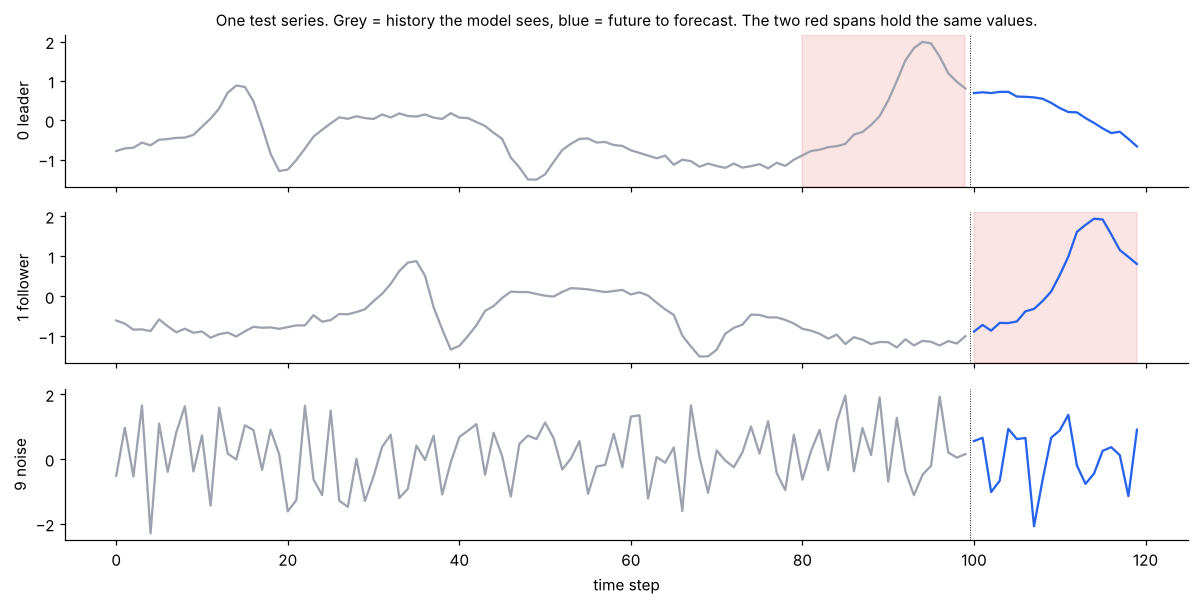

In [2]:
# 20,000 series. The model sees 100 time steps of history and forecasts the next
# 20. Every series has 10 channels.
N_SAMPLES, IN_STEPS, OUT_STEPS, D_IN = 20000, 100, 20, 10
# Three special channels, built so that WE KNOW the right explanation:
#   channel 0 "leader"   : a wave with random bumps
#   channel 1 "follower" : a copy of the leader, 20 steps later (LAG = 20)
#                          -> the follower's future can only be read from the
#                          leader's last 20 steps
#   channel 9 "noise"    : pure random noise -> nothing can predict it, and it
#   predicts nothing
LEADER, FOLLOWER, NOISE, LAG = 0, 1, 9, 20
# Names for the plots.
CHANNELS = (
    ["0 leader", "1 follower"]
    + [f"{d} wave" for d in range(2, 9)]
    + ["9 noise"]
)


def make_data(n=N_SAMPLES, seed=SEED):
    # A random number generator with a fixed seed.
    rng = np.random.default_rng(seed)
    # Every series has 100 + 20 = 120 steps.
    total = IN_STEPS + OUT_STEPS
    # The time axis starts 20 steps early, so the follower has something to copy
    # at the beginning.
    t = np.arange(-LAG, total)
    # Every channel is a mix of 2 or 3 sine waves: k = how many, amp = their
    # heights, freq = their speeds, phase = their starting points.
    k = rng.integers(2, 4, (n, 1, D_IN, 1))
    amp = rng.uniform(0.3, 1.2, (n, 1, D_IN, 3)) * (np.arange(3) < k)
    freq = rng.uniform(0.004, 0.02, (n, 1, D_IN, 3))
    phase = rng.uniform(0, 2 * np.pi, (n, 1, D_IN, 3))
    # Add the sine waves up: s has shape (series, time, channel).
    s = (amp * np.sin(2 * np.pi * freq * t[None, :, None, None] + phase)).sum(
        -1
    )
    # Add a slow trend (a line going up or down) and a random offset to every
    # channel.
    s += rng.uniform(-0.01, 0.01, (n, 1, D_IN)) * t[None, :, None] + rng.normal(
        0, 0.1, (n, 1, D_IN)
    )
    # The leader gets 6 bumps at random moments, with random heights, up or
    # down.
    centre = rng.uniform(-LAG, total, (n, 6, 1))
    height = rng.uniform(1.0, 2.0, (n, 6, 1)) * rng.choice([-1, 1], (n, 6, 1))
    # A bump is a bell curve around its centre. Bumps cannot be predicted from
    # the past of the same channel.
    s[:, :, LEADER] += (
        height * np.exp(-0.5 * ((t[None, None, :] - centre) / 2.5) ** 2)
    ).sum(1)
    # A little noise on everything.
    s += rng.normal(0, 0.05, s.shape)
    # Cut off the 20 extra steps at the start.
    data = s[:, LAG:].copy()
    # The follower at time t = the leader at time t - 20 (plus a little noise).
    data[:, :, FOLLOWER] = s[:, :total, LEADER] + rng.normal(
        0, 0.05, (n, total)
    )
    # The noise channel is replaced by pure random numbers.
    data[:, :, NOISE] = rng.normal(0, 1.0, (n, total))
    return torch.tensor(data, dtype=torch.float32)


# Build the data and move it to the GPU/CPU.
data = make_data().to(DEVICE)
# X = the history (first 100 steps), Y = the future to forecast (last 20 steps).
X, Y = data[:, :IN_STEPS], data[:, IN_STEPS:]
# 80% of the series for training, 10% for validation (not used here), the last
# 10% for testing.
n_train, n_val = int(0.8 * N_SAMPLES), int(0.1 * N_SAMPLES)
X_train, Y_train = X[:n_train], Y[:n_train]
X_test, Y_test = X[n_train + n_val :], Y[n_train + n_val :]
print(
    "X_train",
    tuple(X_train.shape),
    "| X_test",
    tuple(X_test.shape),
    "| Y_test",
    tuple(Y_test.shape),
)

# ---- look at one test series: the leader, the follower and the noise channel
fig, axes = plt.subplots(3, 1, figsize=(11, 5.6), sharex=True)
# The time steps of the history (0..99) and of the future (100..119).
t_in, t_out = np.arange(IN_STEPS), np.arange(IN_STEPS, IN_STEPS + OUT_STEPS)
for ax, ch in zip(axes, [LEADER, FOLLOWER, NOISE]):
    # History in grey, future in blue.
    ax.plot(t_in, X_test[0, :, ch].cpu(), color=GREY)
    ax.plot(t_out, Y_test[0, :, ch].cpu(), color=BLUE)
    # A dotted line where the history ends.
    ax.axvline(IN_STEPS - 0.5, color="k", lw=0.6, ls=":")
    ax.set_ylabel(CHANNELS[ch])
# Shade in red the leader's last 20 steps and the follower's future: they hold
# the same values.
axes[0].axvspan(IN_STEPS - LAG, IN_STEPS - 1, color=RED, alpha=0.12)
axes[1].axvspan(IN_STEPS, IN_STEPS + OUT_STEPS - 1, color=RED, alpha=0.12)
axes[0].set_title(
    "One test series. Grey = history the model sees, blue = future to forecast. The two red spans hold the same values.",
    fontsize=10,
)
axes[2].set_xlabel("time step")
plt.tight_layout()
plt.show()

> **What to notice.** In the plot, every bump of the leader appears again in the follower 20 steps later. This is the built-in answer that a good explanation must find.

## 2. The model: the earlier lab's Transformer, in PyTorch · 🟢 core

The blocks are the ones you wrote in the earlier lab: token embedding, sinusoidal positions, multi-head attention, feed-forward, pre-norm encoder and decoder blocks. Three small differences:

- **The attention layer remembers its weights** (`last_attn`), and lets us **replace** them (`override`). That is all the attention experiments need.
- **The decoder input is all zeros**, so each forecast step knows only its position. The earlier lab fed in the shifted target (teacher forcing) and then generated one step at a time. On this data the errors of that loop build up, and one forward pass is easier to explain.
- **Size:** `d_model = 32`, 4 heads, one encoder block and one decoder block.

> **What this cell does.** **You can skip reading this cell; just run it.** It builds the Transformer from your earlier lab in PyTorch and trains it for about a minute.

In [3]:
# This cell rebuilds the Transformer of the earlier lab and trains it. The
# parts, from small to large:


# ---------- positional encoding: tell the model WHERE in time each step is
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        # pos = the positions 0, 1, 2, ... as a column; i = the numbers of the
        # d_model dimensions as a row.
        pos = torch.arange(max_len)[:, None]
        i = torch.arange(d_model)[None, :]
        # Each pair of dimensions gets its own wavelength, from very short to
        # very long.
        ang = pos / torch.pow(10000.0, (2 * (i // 2)) / d_model)
        # Even dimensions hold a sine, odd dimensions a cosine: every position
        # gets its own pattern of numbers.
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(ang[:, 0::2])
        pe[:, 1::2] = torch.cos(ang[:, 1::2])
        # Store the table inside the module (it is fixed, not trained).
        self.register_buffer("pe", pe[None])

    # Add the pattern of each position to the input at that position.
    def forward(self, x):
        return x + self.pe[:, : x.shape[1]]


# ---------- attention: every "query" step looks at all "key" steps and takes a
# weighted average of them
# Self-attention: a sequence looks at itself (kv is None). Cross-attention: the
# forecast steps (x) look at the history (kv).
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        # h = the number of heads (4), d = the size of each head. Each head is
        # one independent attention pattern.
        self.h, self.d = num_heads, d_model // num_heads
        # Four linear layers: for the queries, the keys, the values, and the
        # output.
        self.q, self.k, self.v, self.proj = (
            nn.Linear(d_model, d_model) for _ in range(4)
        )
        # We keep the attention weights of the last run here, so we can LOOK at
        # them later:
        # shape (batch, heads, queries, keys); every row (one query) adds up to
        # 1.
        self.last_attn = None
        # If we put a function here, it REPLACES the attention weights. Section
        # 7 uses this for a test.
        self.override = None

    def forward(self, x, kv=None, mask=None):
        # The sequence we look AT: x itself (self-attention) or kv
        # (cross-attention).
        src = x if kv is None else kv
        # B = batch size, Tq = number of queries (steps that look), Tk = number
        # of keys (steps that are looked at).
        B, Tq, Tk = x.shape[0], x.shape[1], src.shape[1]
        # A helper that cuts a tensor (B, T, d_model) into the heads: (B, heads,
        # T, d).
        split = lambda z, T: z.view(B, T, self.h, self.d).transpose(1, 2)
        # Queries from x; keys and values from the sequence we look at.
        q, k, v = (
            split(self.q(x), Tq),
            split(self.k(src), Tk),
            split(self.v(src), Tk),
        )
        # 1. SCORE: how well does each query match each key? (a dot product,
        # scaled) -> (B, heads, Tq, Tk)
        att = q @ k.transpose(-1, -2) * self.d**-0.5
        # Where the mask is True the query is not allowed to look: give those
        # places a very low score.
        if mask is not None:
            att = att.masked_fill(mask, -1e9)
        # 2. NORMALISE: softmax turns the scores of each query into weights that
        # add up to 1. These are "the attention weights".
        att = att.softmax(-1)
        # (For the test in section 7: replace the weights if an override
        # function is set.)
        if self.override is not None:
            att = self.override(att)
        # Remember the weights, so we can plot them.
        self.last_attn = att.detach()
        # 3. MIX: each query's output = the weighted average of the values. Then
        # glue the heads back together and apply the output layer.
        return self.proj((att @ v).transpose(1, 2).reshape(B, Tq, -1))


# ---------- a small two-layer network applied at every time step ----------
class FeedForward(nn.Sequential):
    def __init__(self, d, ratio, p):
        super().__init__(
            nn.Linear(d, d * ratio),
            nn.GELU(),
            nn.Dropout(p),
            nn.Linear(d * ratio, d),
            nn.Dropout(p),
        )


# ---------- encoder block: reads the history ----------
class EncoderBlock(nn.Module):
    def __init__(self, d, h, ratio, p):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = MultiHeadAttention(d, h)
        self.ffn = FeedForward(d, ratio, p)

    def forward(self, x):
        # Self-attention: every history step looks at all history steps. "x +
        # ..." keeps the input and adds the new information.
        x = x + self.attn(self.norm1(x))
        # Then the small network.
        return x + self.ffn(self.norm2(x))


# ---------- decoder block: writes the forecast ----------
class DecoderBlock(nn.Module):
    def __init__(self, d, h, ratio, p):
        super().__init__()
        self.norm1, self.norm2, self.norm3 = (
            nn.LayerNorm(d),
            nn.LayerNorm(d),
            nn.LayerNorm(d),
        )
        self.self_attn, self.cross_attn = MultiHeadAttention(
            d, h
        ), MultiHeadAttention(d, h)
        self.ffn = FeedForward(d, ratio, p)

    def forward(self, x, memory, tgt_mask):
        # Self-attention among the forecast steps; the mask stops a step from
        # looking at later steps.
        x = x + self.self_attn(self.norm1(x), mask=tgt_mask)
        # CROSS-ATTENTION: every forecast step looks at the encoded history
        # (`memory`).
        # This is the only place where the forecast gets information from the
        # history, and it is the layer we will inspect.
        x = x + self.cross_attn(self.norm2(x), kv=memory)
        # Then the small network.
        return x + self.ffn(self.norm3(x))


# ---------- the whole model ----------
class TimeSeriesTransformer(nn.Module):
    def __init__(
        self,
        d_model=32,
        num_heads=4,
        depth_enc=1,
        depth_dec=1,
        mlp_ratio=2,
        dropout=0.1,
        d_in=D_IN,
    ):
        super().__init__()
        # Turn the 10 channel values of a time step into a vector of 32 numbers
        # (one layer for the history, one for the forecast side).
        self.enc_tok, self.dec_tok = nn.Linear(d_in, d_model), nn.Linear(
            d_in, d_model
        )
        self.pos = PositionalEncoding(d_model)
        self.drop = nn.Dropout(dropout)
        # One encoder block and one decoder block.
        self.encoders = nn.ModuleList(
            EncoderBlock(d_model, num_heads, mlp_ratio, dropout)
            for _ in range(depth_enc)
        )
        self.decoders = nn.ModuleList(
            DecoderBlock(d_model, num_heads, mlp_ratio, dropout)
            for _ in range(depth_dec)
        )
        # Turn the 32 numbers of each forecast step back into 10 channel values.
        self.head = nn.Linear(d_model, d_in)

    def forward(self, enc, dec_in):
        # Encode the history: embed, add positions, run the encoder block(s).
        # `memory` = what the model knows about the history.
        memory = self.drop(self.pos(self.enc_tok(enc)))
        for blk in self.encoders:
            memory = blk(memory)
        # The mask for the decoder: True above the diagonal = "step i may not
        # look at steps after i".
        T = dec_in.shape[1]
        mask = torch.triu(
            torch.ones(T, T, dtype=torch.bool, device=dec_in.device), 1
        )
        # Decode: embed the decoder input, add positions, run the decoder
        # block(s), and map to the 10 channels.
        x = self.drop(self.pos(self.dec_tok(dec_in)))
        for blk in self.decoders:
            x = blk(x, memory, mask)
        return self.head(x)


# ---------- forecast: history in, forecast out ----------
# The decoder input is all zeros (20 empty slots), so the forecast depends ONLY
# on the history: (B, 100, 10) -> (B, 20, 10).
# It is one ordinary forward pass, so PyTorch can compute gradients through it.
# IG needs that.
def forecast(enc):
    return model(
        enc,
        torch.zeros(enc.shape[0], OUT_STEPS, enc.shape[2], device=enc.device),
    )


# ---------- training: the usual loop ----------
EPOCHS, BATCH, LR = 12, 128, 2e-3
model = TimeSeriesTransformer().to(DEVICE)
# Adam changes the weights; the scheduler raises the learning rate at first and
# then lowers it.
opt = torch.optim.Adam(model.parameters(), LR)
sched = torch.optim.lr_scheduler.OneCycleLR(
    opt, LR, total_steps=EPOCHS * ((n_train + BATCH - 1) // BATCH)
)
t0 = time.time()
for epoch in range(EPOCHS):
    # Training mode (dropout on); `total` adds up the error of this epoch.
    model.train()
    total = 0.0
    # Shuffle the training series and cut them into batches.
    for b in torch.randperm(n_train, device=DEVICE).split(BATCH):
        # Forecast, measure the mean squared error, compute the gradients, take
        # one step.
        loss = nn.functional.mse_loss(forecast(X_train[b]), Y_train[b])
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        total += loss.item() * len(b)
    print(
        f"epoch {epoch + 1:2d}/{EPOCHS}   training MSE {total / n_train:.3f}   ({time.time() - t0:.0f} s)"
    )
# Training is over: evaluation mode, and freeze the weights (we only need
# gradients with respect to the input from now on).
model.eval()
for p in model.parameters():
    p.requires_grad_(False)
# A short name for the cross-attention layer of the decoder: the layer whose
# weights we will look at.
CROSS = model.decoders[0].cross_attn

epoch  1/12   training MSE 1.340   (6 s)


epoch  2/12   training MSE 1.022   (13 s)


epoch  3/12   training MSE 0.599   (19 s)


epoch  4/12   training MSE 0.484   (25 s)


epoch  5/12   training MSE 0.452   (32 s)


epoch  6/12   training MSE 0.432   (38 s)


... (2 outputs left out)

epoch  9/12   training MSE 0.399   (56 s)


epoch 10/12   training MSE 0.393   (61 s)


epoch 11/12   training MSE 0.390   (67 s)


epoch 12/12   training MSE 0.388   (74 s)


### How good is the forecast?

*Predict the mean* is the error of a model that knows nothing. Three things to expect: the **follower** is forecast almost perfectly (its future is on show in the leader), the **noise** channel cannot be forecast at all, and the **leader** is hard because its future bumps are unknown.

,0 leader,1 follower,2 wave,3 wave,4 wave,5 wave,6 wave,7 wave,8 wave,9 noise
Predict the mean,1.675,1.494,1.213,1.200,1.211,1.207,1.233,1.241,1.167,1.001
Transformer,1.022,0.023,0.223,0.217,0.214,0.205,0.213,0.211,0.215,1.001


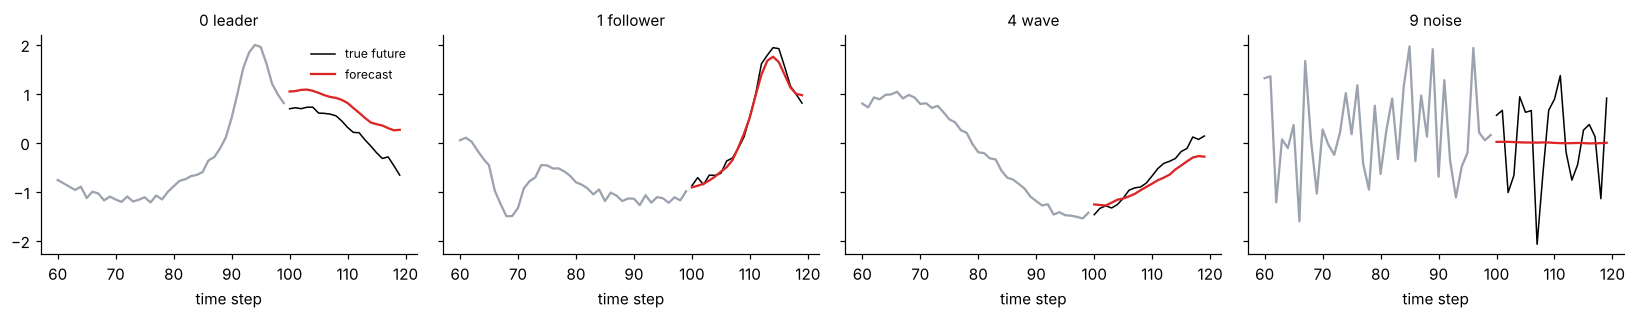

In [4]:
# ---------- channel_mse: how good is the forecast of each channel? ----------
@torch.no_grad()
def channel_mse(Xin, Ytrue=Y_test):
    # Squared error between forecast and truth, averaged over the series
    # (dimension 0) and the 20 forecast steps (dimension 1).
    # What is left is one number per channel: shape (10,).
    return ((forecast(Xin) - Ytrue) ** 2).mean((0, 1)).cpu().numpy()


# BASE = the error on the untouched test set. Every later experiment is compared
# with it.
BASE = channel_mse(X_test)
# A table: the error of a trivial forecast (always predict the channel's
# average) against the Transformer.
display(
    pd.DataFrame(
        {
            "Predict the mean": ((Y_test - Y_train.mean((0, 1))) ** 2)
            .mean((0, 1))
            .cpu()
            .numpy(),
            "Transformer": BASE,
        },
        index=CHANNELS,
    )
    .round(3)
    .T
)

# Forecast the first 8 test series, to plot one of them.
with torch.no_grad():
    P_test = forecast(X_test[:8]).cpu()
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, ch in zip(axes, [LEADER, FOLLOWER, 4, NOISE]):
    # The last 40 steps of the history in grey, the true future in black.
    ax.plot(t_in[60:], X_test[0, 60:, ch].cpu(), color=GREY)
    ax.plot(t_out, Y_test[0, :, ch].cpu(), color="k", lw=1, label="true future")
    # The model's forecast in red.
    ax.plot(t_out, P_test[0, :, ch], color=RED, label="forecast")
    ax.set_title(CHANNELS[ch], fontsize=10)
    ax.set_xlabel("time step")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 3. Model-agnostic: PCI, one input channel at a time · 🟢 core

**Permutation Channel Importance** is the method of the PCI lab: destroy one input channel by **shuffling it across the test series**, leave the model alone, and measure how much the error grows.

There the output was one accuracy. Here the model forecasts 10 channels, so we get a **matrix**: row = the input channel we shuffled, column = the forecast channel whose error we measure.

**The known answer.** Each wave needs only itself (the diagonal). The follower needs the **leader** and not itself. The noise row must be zero.

> **The idea in words.** To test whether the model needs a channel, destroy that channel: give every series the channel of some other series. If the forecasts get worse, the model was using it.

In [5]:
# ---------- permute_channel: destroy the information in ONE input channel
# Idea of PCI (Permutation Channel Importance): if the model needs channel c,
# then giving it the WRONG channel c
# (taken from another series) must make the forecast worse.
#   Xin : a batch of series, shape (N, T, C)      c : the channel to destroy
#         rng : a random number generator
def permute_channel(Xin, c, rng):
    # Work on a copy, so the real test data is not changed.
    Xp = Xin.clone()
    # A random order of the N series, e.g. [3, 0, 2, 1].
    order = torch.as_tensor(rng.permutation(len(Xin)), device=Xin.device)
    # Series i gets channel c of series order[i]. The whole time course of the
    # channel moves together,
    # so the channel still looks realistic; it just no longer belongs to this
    # series. All other channels stay.
    Xp[:, :, c] = Xin[order, :, c]
    return Xp

### ✅ Check: `permute_channel`

In [6]:
# Shuffle channel 3 of the test set with a fixed random generator.
rng = np.random.default_rng(0)
Xp = permute_channel(X_test, 3, rng)
# All channels except channel 3.
others = [c for c in range(D_IN) if c != 3]
# Test 1: same shape, and the other channels are untouched.
assert Xp.shape == X_test.shape and torch.equal(
    Xp[:, :, others], X_test[:, :, others]
), "all channels except c must stay unchanged"
# Test 2: channel 3 really changed.
assert not torch.equal(
    Xp[:, :, 3], X_test[:, :, 3]
), "channel c is unchanged: did you assign the shuffled channel?"
# Test 3: channel 3 holds the same series as before, only in another order (so
# the sum over the series is the same).
assert torch.allclose(
    Xp[:, :, 3].sum(0), X_test[:, :, 3].sum(0), atol=1e-2
), "channel c must hold the same series, in a new order (shuffle whole series, not time steps)"
# Test 4: the original test set was not modified.
assert torch.equal(
    X_test, X[n_train + n_val :]
), "X_test itself must not change: work on the copy"
print("✅ permute_channel is right")

✅ permute_channel is right


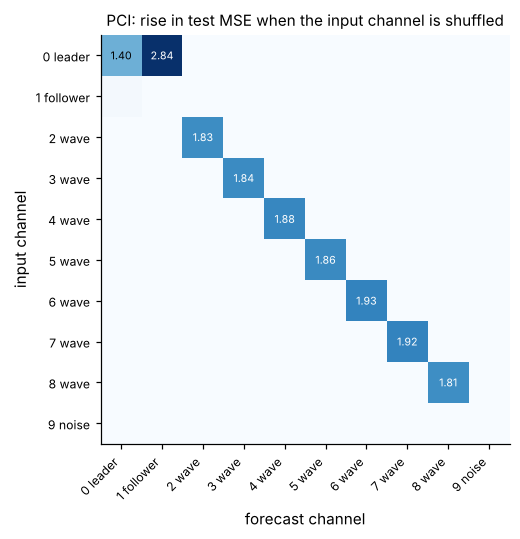

Follower forecast: shuffle the leader -> MSE +2.84;  shuffle the follower itself -> MSE +0.00
Noise channel: largest rise in any forecast = 0.000


In [7]:
# ---------- pci_matrix: PCI for every input channel and every forecast channel
# M[c, d] = how much the error of FORECAST channel d rises when INPUT channel c
# is shuffled.
def pci_matrix(repeats=3, seed=0):
    # A random generator and an empty 10 x 10 table.
    rng = np.random.default_rng(seed)
    M = np.zeros((D_IN, D_IN))
    # Go through the input channels.
    for c in range(D_IN):
        # Shuffling is random, so do it 3 times and average.
        for _ in range(repeats):
            # Error of all 10 forecast channels with input channel c shuffled,
            # minus the normal error BASE.
            # This fills row c of the table.
            M[c] += (
                channel_mse(permute_channel(X_test, c, rng)) - BASE
            ) / repeats
    return M


# ---------- show_matrix: draw such a 10 x 10 table as a heat map (rows = input
# channels, columns = forecast channels)
def show_matrix(ax, M, title, fmt="{:.2f}", cmap="Blues"):
    # Darker blue = larger value. Channel names on both axes.
    im = ax.imshow(M, cmap=cmap, vmin=0)
    ax.set_xticks(range(D_IN))
    ax.set_yticks(range(D_IN))
    ax.set_xticklabels(CHANNELS, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(CHANNELS, fontsize=8)
    # Write the number into every cell that is not tiny (white text on dark
    # cells).
    for r in range(D_IN):
        for c in range(D_IN):
            if abs(M[r, c]) >= 0.05 * M.max():
                ax.text(
                    c,
                    r,
                    fmt.format(M[r, c]),
                    ha="center",
                    va="center",
                    fontsize=7,
                    color="white" if M[r, c] > 0.6 * M.max() else "k",
                )
    ax.set_xlabel("forecast channel")
    ax.set_ylabel("input channel")
    ax.set_title(title, fontsize=10)


# Compute the PCI table and draw it.
PCI = pci_matrix()
fig, ax = plt.subplots(figsize=(5.6, 5))
show_matrix(ax, PCI, "PCI: rise in test MSE when the input channel is shuffled")
plt.tight_layout()
plt.show()
# Two things we know must be true. (1) The follower's forecast needs the
# LEADER's history, not its own.
print(
    f"Follower forecast: shuffle the leader -> MSE +{PCI[LEADER, FOLLOWER]:.2f};  shuffle the follower itself -> MSE +{PCI[FOLLOWER, FOLLOWER]:.2f}"
)
# (2) The noise channel helps no forecast, so shuffling it should change
# nothing.
print(
    f"Noise channel: largest rise in any forecast = {np.abs(PCI[NOISE]).max():.3f}"
)

## 4. Model-specific: Integrated Gradients for single forecasts · 🟢 core

PCI is **global**: one number per channel for the whole test set. IG is **local**: it explains one forecast of one series, and it can also say *which time step*.

`integrated_gradients` is the function you wrote in Sequence lab 1. The baseline is a history of zeros.

For one series and one forecast channel, IG gives a table of **100 time steps × 10 input channels**. To compare with PCI, add up the size of the attributions over time: one number per input channel. Do this for every forecast channel, average over a few series, and you get a matrix with the same layout as PCI.

To put the two side by side, each column is divided by its sum: *of everything this forecast's explanation points at, what share goes to each input channel?* The noise forecast is left blank: it is a constant, so there is nothing to explain.

> **The idea in words.** IG (from sequence lab 1) gives a value to every input number: 100 time steps × 10 channels. To compare with PCI we add the sizes of these values over time, which leaves one number per input channel.

In [8]:
# ---------- Integrated Gradients, the same function as in the RNN lab
#   f : maps a batch (B, T, C) to B numbers      x, baseline : one series each,
#       shape (T, C)
def integrated_gradients(f, x, baseline, steps=32):
    # `steps` numbers between 0 and 1: 0 = at the baseline, 1 = at x.
    alphas = (torch.arange(steps, device=x.device) + 0.5) / steps
    # All points on the straight line from the baseline to x, as one batch
    # (steps, T, C); we want gradients for them.
    path = (baseline + alphas.view(-1, 1, 1) * (x - baseline)).requires_grad_(
        True
    )
    # The gradient of the output with respect to the input, at every point on
    # the line.
    grads = torch.autograd.grad(f(path).sum(), path)[0]
    # Attribution = (average gradient along the line) x (distance moved from the
    # baseline). Shape (T, C).
    return ((x - baseline) * grads.mean(0)).detach()


# ---------- ig_channel_matrix: the same kind of 10 x 10 table as PCI, but from
# IG
# G[c, d] = how much INPUT channel c contributes to the forecast of channel d,
# averaged over 20 test series.
def ig_channel_matrix(n_series=20):
    # An empty 10 x 10 table.
    G = torch.zeros(D_IN, D_IN, device=DEVICE)
    for x in X_test[:n_series]:
        for d in range(D_IN):
            # IG explains ONE number. Our model outputs 20 steps x 10 channels,
            # so we must choose what to explain:
            # here, the forecast of channel d added up over its 20 steps.
            f = lambda z: forecast(z)[:, :, d].sum(1)
            # IG with a zero baseline: one attribution per input time step and
            # input channel, shape (100, 10).
            a = integrated_gradients(f, x, torch.zeros_like(x))
            # Take absolute values and add them over the 100 time steps: one
            # number per input channel. This fills column d.
            G[:, d] += a.abs().sum(0) / n_series
    return G.cpu().numpy()

### ✅ Check: the IG channel matrix

In [9]:
# Compute the IG table.
IG = ig_channel_matrix()
# Test 1: a 10 x 10 table without negative numbers (we took absolute values).
assert (
    IG.shape == (D_IN, D_IN) and (IG >= 0).all()
), "the matrix must be 10 x 10 and non-negative (absolute attributions)"
# Test 2, completeness: for one series and forecast channel 4, the attributions
# must add up to f(x) - f(baseline).
x = X_test[0]
a = integrated_gradients(
    lambda z: forecast(z)[:, :, 4].sum(1), x, torch.zeros_like(x), steps=128
)
gap = float(
    forecast(x[None])[0, :, 4].sum()
    - forecast(torch.zeros_like(x)[None])[0, :, 4].sum()
)
assert abs(float(a.sum()) - gap) < 0.05 * max(
    1.0, abs(gap)
), "completeness fails: is f the forecast of channel d added over the steps?"
# Test 3: each plain wave (channels 2 to 8) can only be forecast from its own
# history, so its own row must be the largest.
assert all(
    IG[:, d].argmax() == d for d in range(2, 9)
), "each wave's forecast should lean most on its own channel"
print("✅ the IG channel matrix is right")

✅ the IG channel matrix is right


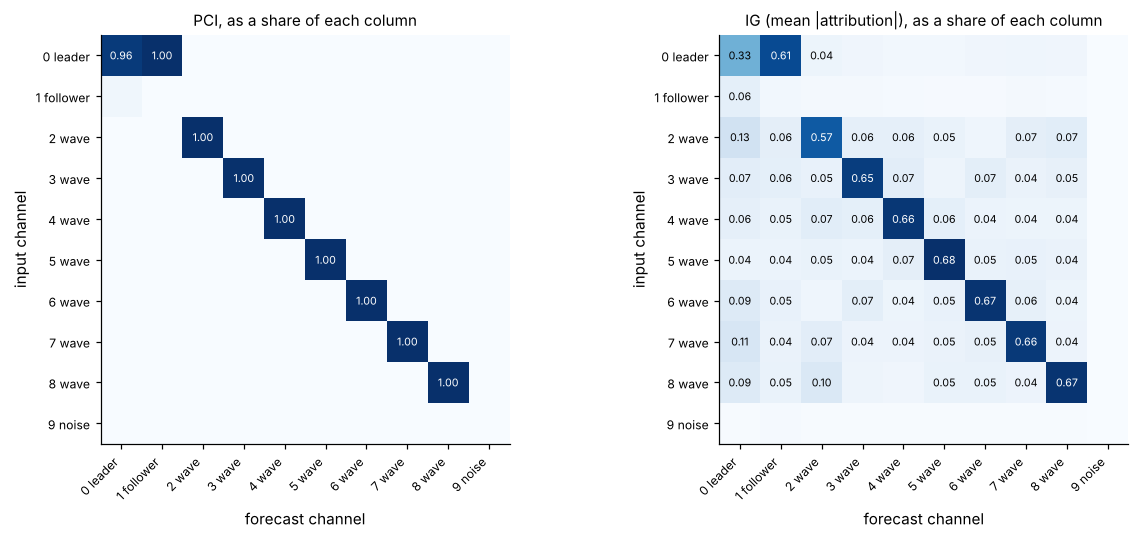

,0 leader,1 follower,2 wave,3 wave,4 wave,5 wave,6 wave,7 wave,8 wave
share of the explanation on the right input channel,,,,,,,,,
PCI,0.96,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
IG,0.33,0.61,0.57,0.65,0.66,0.68,0.67,0.66,0.67


Share on the noise input, averaged over the forecasts:  PCI 0.000   IG 0.005


In [10]:
# PCI and IG use different units (rise in error / attribution). To compare them,
# turn every column into shares:
def share(M):
    # The total of each column (one column = one forecast channel).
    total = M.sum(0)
    # Divide each column by its total, so it adds up to 1. Columns with almost
    # nothing to explain
    # (like the noise forecast) are divided by infinity, which leaves them at 0
    # (blank).
    return M / np.where(total > 0.02 * total.max(), total, np.inf)


# The two tables side by side. (np.clip(PCI, 0, None) sets small negative PCI
# values to 0.)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
show_matrix(
    axes[0], share(np.clip(PCI, 0, None)), "PCI, as a share of each column"
)
show_matrix(
    axes[1], share(IG), "IG (mean |attribution|), as a share of each column"
)
plt.tight_layout()
plt.show()

# TRUTH marks the input channel that each forecast can REALLY use: its own
# channel (the diagonal),
# except for the follower, whose forecast must come from the leader.
TRUTH = np.eye(D_IN, dtype=bool)
TRUTH[LEADER, FOLLOWER] = True
TRUTH[FOLLOWER, FOLLOWER] = False
# All forecast channels except the noise (nothing can forecast noise).
cols = [d for d in range(D_IN) if d != NOISE]
# A table: for each forecast channel, the share of the explanation that lands on
# the right input channel (1.0 = perfect).
display(
    pd.DataFrame(
        {
            "PCI": [
                share(np.clip(PCI, 0, None))[:, d][TRUTH[:, d]].sum()
                for d in cols
            ],
            "IG": [share(IG)[:, d][TRUTH[:, d]].sum() for d in cols],
        },
        index=[CHANNELS[d] for d in cols],
    )
    .round(2)
    .T.rename_axis("share of the explanation on the right input channel")
)
# And the share that lands on the noise input (should be close to 0).
print(
    f"Share on the noise input, averaged over the forecasts:  PCI {share(np.clip(PCI, 0, None))[NOISE, cols].mean():.3f}   IG {share(IG)[NOISE, cols].mean():.3f}"
)

## 5. Which moment? The 20-step delay as a known answer · 🟢 core

Now use what PCI cannot give: **time**. Explain the follower's forecast at **one** forecast step $h$ (0 to 19) and keep the attributions on the **leader** channel. The data says where they must be: the follower at step $100 + h$ is the leader at step $80 + h$.

So in a map with one row per forecast step and one column per input time step, a correct explanation is a **diagonal line** from (0, 80) to (19, 99).

For contrast, do the same for a plain wave (channel 4) and its own history: there is no delay to find, so the model should lean on the most recent steps.

> **What this cell does.** It asks IG *which moment* of the leader each forecast step of the follower uses.

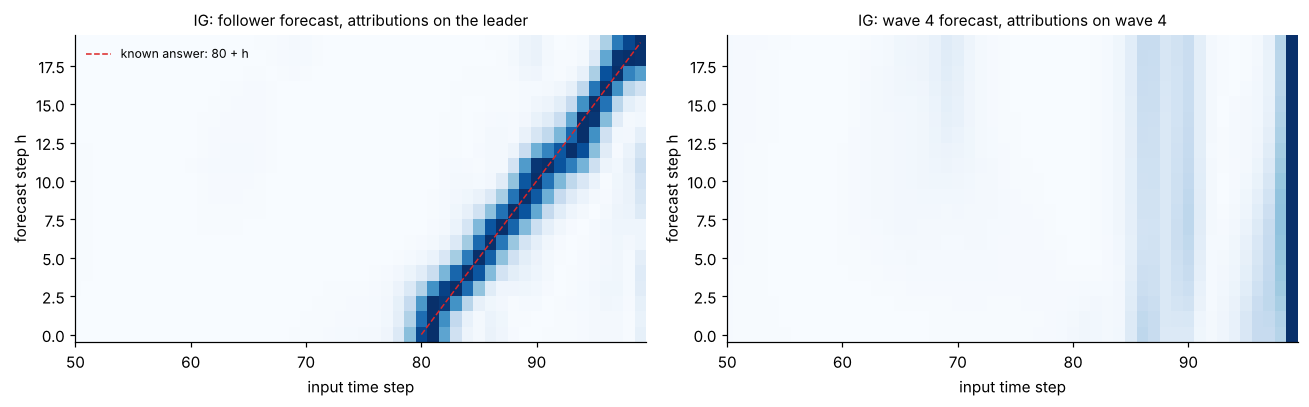

Follower: the IG peak is within 1 step of the known answer for 20 of 20 forecast steps
Wave 4:   the IG peak is at input step [99]


In [11]:
# ---------- ig_time_map: WHICH TIME STEPS of the history does each forecast
# step use?
# Result: a table with one row per forecast step h (20 rows) and one column per
# input time step (100 columns).
def ig_time_map(out_ch, in_ch, n_series=30):
    # An empty 20 x 100 table.
    Mh = torch.zeros(OUT_STEPS, IN_STEPS, device=DEVICE)
    for x in X_test[:n_series]:
        for h in range(OUT_STEPS):
            # Explain ONE number: the forecast of channel out_ch at forecast
            # step h.
            a = integrated_gradients(
                lambda z: forecast(z)[:, h, out_ch], x, torch.zeros_like(x)
            )
            # Keep the attributions on input channel in_ch (one per input time
            # step), in absolute value, averaged over the series.
            Mh[h] += a[:, in_ch].abs() / n_series
    return Mh.cpu().numpy()


# Two maps: (1) the follower's forecast explained on the leader's history; (2)
# wave 4's forecast explained on its own history.
IG_FOLLOWER, IG_WAVE = ig_time_map(FOLLOWER, LEADER), ig_time_map(4, 4)


# ---------- show_time_map: draw such a table (forecast step on the vertical
# axis, input time step on the horizontal axis)
def show_time_map(ax, M, title, diagonal=True):
    # Divide each row by its largest value, so every forecast step shows its own
    # peak clearly. Darker = more important.
    ax.imshow(
        M / M.max(1, keepdims=True),
        cmap="Blues",
        aspect="auto",
        origin="lower",
        extent=[-0.5, IN_STEPS - 0.5, -0.5, OUT_STEPS - 0.5],
    )
    # The red dashed line is the KNOWN answer for the follower: forecast step h
    # copies the leader at input step 80 + h.
    if diagonal:
        ax.plot(
            [IN_STEPS - LAG, IN_STEPS - 1],
            [0, OUT_STEPS - 1],
            color=RED,
            lw=1,
            ls="--",
            label="known answer: 80 + h",
        )
    # Show only the last 50 input steps.
    ax.set_xlim(50, IN_STEPS - 0.5)
    ax.set_xlabel("input time step")
    ax.set_ylabel("forecast step h")
    ax.set_title(title, fontsize=10)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
show_time_map(
    axes[0], IG_FOLLOWER, "IG: follower forecast, attributions on the leader"
)
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
show_time_map(
    axes[1],
    IG_WAVE,
    "IG: wave 4 forecast, attributions on wave 4",
    diagonal=False,
)
plt.tight_layout()
plt.show()
# Count for how many of the 20 forecast steps the strongest input step is the
# known answer 80 + h (give or take 1 step).
hit = (
    np.abs(IG_FOLLOWER.argmax(1) - (IN_STEPS - LAG + np.arange(OUT_STEPS))) <= 1
)
print(
    f"Follower: the IG peak is within 1 step of the known answer for {hit.sum()} of {OUT_STEPS} forecast steps"
)
# For the wave: which input steps are the strongest? (We expect the most recent
# ones.)
print(
    "Wave 4:   the IG peak is at input step",
    sorted(set(IG_WAVE.argmax(1).tolist())),
)

> **What to notice.** Left: the dark cells follow the dashed line, so IG finds the 20-step delay. Right: a plain wave just looks at its own most recent steps.

## 6. Attention: does the map show the delay? · 🟢 core

The decoder's **cross-attention** is where forecast steps look at the history. Its weights have the right shape for an explanation: one row per forecast step, one column per input time step, each row adding up to 1.

Two limits are built in before we look:

- **One map for all channels.** A token is a whole time step (all 10 channels), so attention can say *when*, never *which channel*. The follower and wave 4 get the same map, although section 5 showed they use the history differently.
- **Four heads.** Each head has its own map. The usual picture averages them.

> **What this cell does.** It draws the attention weights of the decoder: for each forecast step (row), how much it looks at each input step (column). First the average of the 4 heads, then each head.

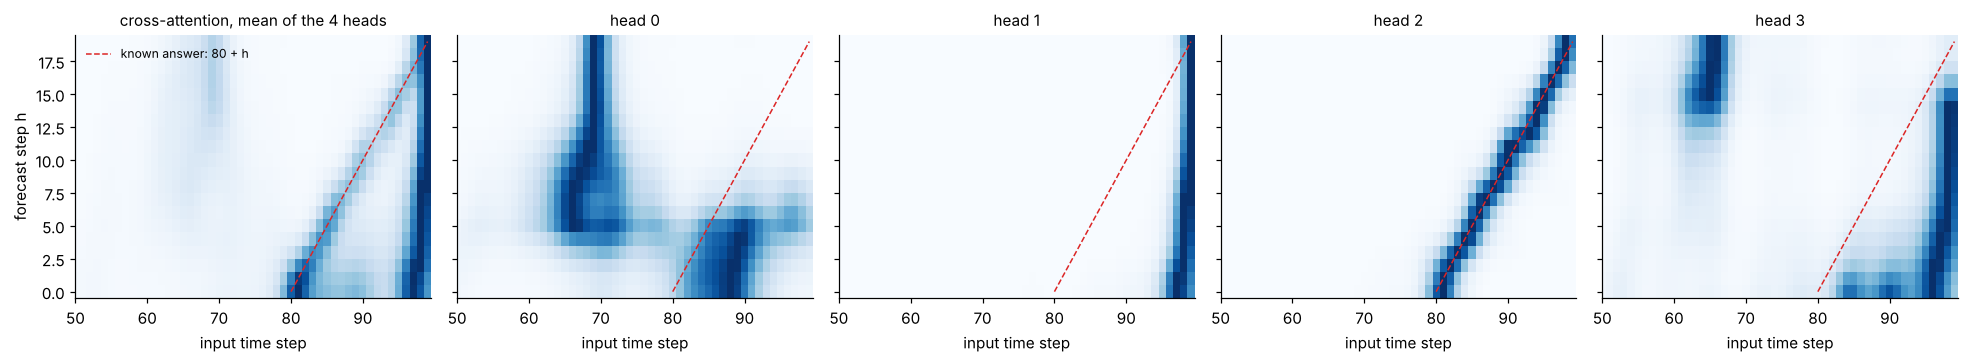

,mean of heads,head 0,head 1,head 2,head 3
forecast steps whose peak is within 1 step of 80 + h,3.00,0.00,2.00,20.00,0.00
forecast steps whose peak is in the last 5 inputs,19.00,0.00,20.00,5.00,15.00
"rank correlation with IG, follower",0.53,0.22,0.60,0.56,0.50
"rank correlation with IG, wave 4",0.56,0.32,0.52,0.48,0.46


In [12]:
# Run the model on 500 test series. We do not need the forecasts: we want the
# attention weights that the run leaves behind.
with torch.no_grad():
    forecast(X_test[:500])
# The cross-attention weights of that run, averaged over the 500 series: (4
# heads, 20 forecast steps, 100 input steps).
# ATT[k, h, t] = how much forecast step h "looks at" input step t in head k.
ATT = CROSS.last_attn.mean(0).cpu().numpy()

# Five maps: the average of the 4 heads, then each head. Same kind of picture as
# the IG maps above.
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4), sharey=True)
show_time_map(axes[0], ATT.mean(0), "cross-attention, mean of the 4 heads")
for k in range(4):
    show_time_map(axes[k + 1], ATT[k], f"head {k}")
for ax in axes[1:]:
    ax.set_ylabel("")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

# The known answer for the follower: forecast step h should look at input step
# 80 + h.
answer = IN_STEPS - LAG + np.arange(OUT_STEPS)
# The five maps to score: the mean of the heads and each head.
rows = {"mean of heads": ATT.mean(0), **{f"head {k}": ATT[k] for k in range(4)}}
# For each map, four numbers:
#   - for how many forecast steps the attention peak is at the known answer
#   (give or take 1 step)
#   - for how many forecast steps the peak is simply in the last 5 inputs
#   - how well the attention map agrees with the IG map of the follower (rank
#   correlation, per forecast step, averaged)
#   - the same for the IG map of wave 4
display(
    pd.DataFrame(
        {
            name: {
                "forecast steps whose peak is within 1 step of 80 + h": int(
                    (np.abs(A.argmax(1) - answer) <= 1).sum()
                ),
                "forecast steps whose peak is in the last 5 inputs": int(
                    (A.argmax(1) >= IN_STEPS - 5).sum()
                ),
                "rank correlation with IG, follower": np.mean(
                    [
                        spearmanr(A[h], IG_FOLLOWER[h])[0]
                        for h in range(OUT_STEPS)
                    ]
                ),
                "rank correlation with IG, wave 4": np.mean(
                    [spearmanr(A[h], IG_WAVE[h])[0] for h in range(OUT_STEPS)]
                ),
            }
            for name, A in rows.items()
        }
    ).round(2)
)

> **What to notice.** The average map hides the delay. One single head follows the dashed line. Looking only at the average would mislead you.

## 7. Is the attention used? Replace the weights · 🟢 core

A map can look meaningful and still not matter (lab S10: on BiLSTM states, shuffling the attention changed few predictions). The test is the same here: **keep the model and the input, change only the cross-attention weights, and watch the error.**

- **Uniform:** every input step gets the same weight, 1/100.
- **Shuffled in time:** the same weights, moved to other input steps.
- **Shifted by 5:** every weight moves 5 steps into the past. If the model reads the leader at step $80 + h$ through attention, it now reads step $85 + h$: the wrong moment.

> **The idea in words.** To test whether the attention weights matter, replace them and watch the error. `uniform` makes all weights equal; `shuffled` moves them to random places; `shifted` moves them 5 steps into the past.

In [13]:
# ---------- the replace-the-attention test ----------
# If the attention weights really are the explanation ("the model looks HERE"),
# then replacing them by other weights
# must hurt the forecast. Three replacements. In all of them:
#   att has shape (batch, heads, queries, keys) = (series, 4 heads, 20 forecast
#   steps, 100 input steps),
#   and att.shape[-1] is the number of keys = 100.


def uniform(att):
    # Look at every input step equally: every weight becomes 1/100. (Each row
    # still adds up to 1.)
    return torch.full_like(att, 1.0 / att.shape[-1])


def shuffled(att):
    # Keep the same weights but move them to random input steps: the model now
    # "looks" at the wrong moments.
    # torch.randperm(100) is a random order of the 100 input steps; indexing the
    # last dimension with it reorders the keys.
    return att[..., torch.randperm(att.shape[-1], device=att.device)]


def shifted(att, by=5):
    # Move every weight 5 input steps into the past: the model looks 5 steps too
    # early.
    # (torch.roll wraps around: the first 5 weights reappear at the end.)
    return torch.roll(att, -by, dims=-1)

### ✅ Check: `uniform` and `shuffled`

In [14]:
# Take the attention weights of 4 series from the last run.
A0 = CROSS.last_attn[:4]
U, S = uniform(A0), shuffled(A0)
# uniform: same shape, and every weight equals 1/100.
assert U.shape == A0.shape and torch.allclose(
    U, torch.full_like(A0, 1 / IN_STEPS)
), "uniform: every weight must be 1/100"
# shuffled: same shape, and every row still adds up to 1 ...
assert S.shape == A0.shape and torch.allclose(
    S.sum(-1), A0.sum(-1), atol=1e-5
), "shuffled: every row must still add up to 1"
# ... because it holds exactly the same weights (compare them after sorting),
# but in a different order.
assert torch.allclose(
    S.sort(-1).values, A0.sort(-1).values
) and not torch.equal(
    S, A0
), "shuffled: the same weights in each row, in a new order"
print("✅ uniform and shuffled are right")

✅ uniform and shuffled are right


In [15]:
# ---------- mse_with: the test error when the cross-attention weights are
# replaced
def mse_with(override):
    # Fix the random seed (for `shuffled`), and plug the replacement function
    # into the cross-attention layer.
    torch.manual_seed(0)
    CROSS.override = override
    # Measure the error of every forecast channel with the replaced attention
    # ...
    try:
        return channel_mse(X_test)
    # ... and ALWAYS give the model its own attention back afterwards, even if
    # something goes wrong.
    finally:
        CROSS.override = None


show = [LEADER, FOLLOWER, 4, NOISE]
# One column per experiment: the model's own attention, then the three
# replacements. One row per channel.
table = pd.DataFrame(
    {
        "own attention": BASE,
        "uniform": mse_with(uniform),
        "shuffled in time": mse_with(shuffled),
        "shifted by 5": mse_with(shifted),
    },
    index=CHANNELS,
)
# One extra row: the average over the seven plain waves.
table.loc["mean of waves 2-8"] = table.iloc[2:9].mean()
# Show the four interesting rows. If a replacement barely changes the error, the
# forecast did not depend on WHERE the attention looked.
display(
    table.loc[["0 leader", "1 follower", "mean of waves 2-8", "9 noise"]]
    .round(3)
    .rename_axis("test MSE")
)

,own attention,uniform,shuffled in time,shifted by 5
test MSE,,,,
0 leader,1.022,1.342,1.325,1.070
1 follower,0.023,1.227,1.404,0.605
mean of waves 2-8,0.214,1.593,1.390,0.425
9 noise,1.001,1.001,1.001,1.001


## 8. What did you find?

When this notebook was built, the numbers were (they move with the random seed and between CPU and GPU; which head does what can change too):

| 2,000 test series | Result |
|---|---|
| Test MSE (predict the mean: about 1.2 for the waves) | follower 0.02, waves 0.21, leader 1.02, noise 1.00 |
| PCI, follower forecast | shuffle the leader: MSE +2.84; shuffle the follower itself: +0.00 |
| PCI, noise input | 0.000 for every forecast |
| IG, share of the explanation on the right input channel | follower 0.61, waves 0.57 to 0.68; noise input 0.005 |
| IG, peak within 1 step of 80 + h | 20 of 20 forecast steps |
| Attention, peak within 1 step of 80 + h | mean of heads: 3 of 20; one head (head 2): 20 of 20; another head (head 1) stays on the last 5 inputs |
| MSE with uniform attention | follower 1.23, waves 1.59 |
| MSE with attention shifted by 5 steps | follower 0.61, waves 0.43 |

Answer in one or two sentences each.

1. PCI and IG were both marked against the known answer. Where did each one put the follower's forecast? Which one gave the cleaner answer, and what can IG tell you that PCI cannot?
2. IG puts a small share of every forecast on channels that cannot matter. PCI does not. Give one reason. Think about what each method compares the input with.
3. Look at the heads one by one, then at their mean. What would you have concluded about the 20-step delay from the mean map alone?
4. In lab S10, shuffling the attention on BiLSTM states changed few predictions. Here, replacing the cross-attention breaks the forecast. What is different about where the attention sits in the two models?
5. So: is the cross-attention map an explanation of this model? Say what it gets right, and name two things it cannot tell you.

**Try it.**

- Set `LAG = 10` (and rerun everything). Do the IG diagonal and the attention head move with it?
- Train the model again with `torch.manual_seed(1)`. Is it the same head that tracks the delay? What does that say about reading meaning into "head 2"?
- Occlude a window of 5 time steps of the leader, as in Sequence lab 1, and plot the rise in the follower's error against the window position.

**Where this goes next.** The waves here were *generated* as trend + cycles + noise. Labs D20 (*STL*) and D22 (*N-BEATS, forecast by parts*) build that structure into the model, so the forecast can be read part by part with no explanation method at all.